# Used Car Sales - Exploratory Data Analysis

A simple, beginner-friendly EDA of vehicle sales data pulled from a SQL Server database (`MotoDB.VehicleSales`).

Steps: load data -> look at it -> clean it -> create a couple of new columns -> plot it.

## 1. Import Libraries

In [89]:
import pandas as pd
import numpy as np
import pyodbc
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

## 2. Connect to the Database and Load the Data

In [90]:
# connect to the local SQL Server database
conn = pyodbc.connect(
    r"DRIVER={ODBC Driver 18 for SQL Server};"
    r"SERVER=.\SQLEXPRESS;"
    r"DATABASE=MotoDB;"
    r"Trusted_Connection=yes;"
    r"TrustServerCertificate=yes;"
)
print("Connected successfully")

Connected successfully


In [91]:
# load the whole table into a pandas DataFrame
df = pd.read_sql("SELECT * FROM VehicleSales", conn)
df.head()

C:\Users\aliad\AppData\Local\Temp\ipykernel_22460\2772844504.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("SELECT * FROM VehicleSales", conn)


,Id,Year,Make,Model,Trim,Body,Transmission,VIN,State,ConditionValue,Odometer,Color,Interior,Seller,MMR,SellingPrice,SaleDate
0,2,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0,2014-12-16 04:30:00
1,3,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0,2014-12-16 04:30:00
2,4,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.0,1331.0,gray,black,financial services remarketing (lease),31900.0,30000.0,2015-01-14 20:30:00
3,5,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0,2015-01-28 20:30:00
4,6,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0,2014-12-18 04:30:00


## 3. First Look at the Data

In [92]:
df.shape

(558837, 17)

In [93]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 558837 entries, 0 to 558836
Data columns (total 17 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   Id              558837 non-null  int64         
 1   Year            558837 non-null  int64         
 2   Make            548536 non-null  object        
 3   Model           548438 non-null  object        
 4   Trim            548186 non-null  object        
 5   Body            545642 non-null  object        
 6   Transmission    493485 non-null  object        
 7   VIN             558833 non-null  object        
 8   State           558837 non-null  object        
 9   ConditionValue  547017 non-null  float64       
 10  Odometer        558743 non-null  float64       
 11  Color           558088 non-null  object        
 12  Interior        558088 non-null  object        
 13  Seller          558837 non-null  object        
 14  MMR             558799 non-null  flo

In [94]:
df.describe()

,Id,Year,ConditionValue,Odometer,MMR,SellingPrice,SaleDate
count,558837.000000,558837.000000,547017.000000,558743.000000,558799.000000,558825.000000,558799
mean,279420.000000,2010.038927,30.672365,68320.017767,13769.377495,13611.358810,2015-03-06 00:09:10.521385472
min,2.000000,1982.000000,1.000000,1.000000,25.000000,1.000000,2014-01-01 01:15:00
25%,139711.000000,2007.000000,23.000000,28371.000000,7100.000000,6900.000000,2015-01-20 18:00:00
50%,279420.000000,2012.000000,35.000000,52254.000000,12250.000000,12100.000000,2015-02-12 19:20:00
75%,419129.000000,2013.000000,42.000000,99109.000000,18300.000000,18200.000000,2015-05-21 19:00:00
max,558838.000000,2015.000000,49.000000,999999.000000,182000.000000,230000.000000,2015-07-20 19:30:00
std,161322.490529,3.966864,13.402832,53398.542821,9679.967174,9749.501628,NaN


In [95]:
df.describe(include="object")

,Make,Model,Trim,Body,Transmission,VIN,State,Color,Interior,Seller
count,548536,548438,548186,545642,493485,558833,558837,558088,558088,558837
unique,96,973,1963,87,4,550297,64,46,17,14263
top,Ford,Altima,Base,Sedan,automatic,automatic,fl,black,black,nissan-infiniti lt
freq,93554,19349,55817,199437,475915,22,82945,110970,244329,19693


## 4. Data Quality Assessment

Before cleaning anything, we measure the problems in the raw data: missing values, duplicate rows, repeated Ids and VINs, and the quality of the text columns. These cells only read the data - they do not change it.

In [96]:
df.isnull().sum()

Id                    0
Year                  0
Make              10301
Model             10399
Trim              10651
Body              13195
Transmission      65352
VIN                   4
State                 0
ConditionValue    11820
Odometer             94
Color               749
Interior            749
Seller                0
MMR                  38
SellingPrice         12
SaleDate             38
dtype: int64

In [97]:
# same thing, shown as a percentage
(df.isnull().sum() / len(df) * 100).round(2)

Id                 0.00
Year               0.00
Make               1.84
Model              1.86
Trim               1.91
Body               2.36
Transmission      11.69
VIN                0.00
State              0.00
ConditionValue     2.12
Odometer           0.02
Color              0.13
Interior           0.13
Seller             0.00
MMR                0.01
SellingPrice       0.00
SaleDate           0.01
dtype: float64

In [98]:
# ignore the Id column when checking for duplicates - every row has a different Id,
# so comparing including Id would never find a real duplicate
df.duplicated(subset=df.columns.drop("Id")).sum()

np.int64(0)

### Duplicate Id

**What:** count how many `Id` values appear more than once.

**Why:** `Id` should be unique for every row. A repeated `Id` would mean the same record was loaded twice. (This is only a check - nothing is removed here.)

In [99]:
dup_ids = df["Id"].duplicated(keep=False)
print("Ids that appear more than once:", df.loc[dup_ids, "Id"].nunique())
print("Rows with a repeated Id:", dup_ids.sum())

Ids that appear more than once: 0
Rows with a repeated Id: 0


### Repeated VIN

**What:** count how many VINs appear more than once, and how many of those rows also share the same `SaleDate` + `Seller`.

**Why:** a VIN identifies one physical car, so repeats are worth knowing about. Only a repeat with the same sale date and seller looks like an accidental double entry.

In [100]:
vin = df["VIN"].dropna()
repeated_vins = vin[vin.duplicated(keep=False)]
print("VINs that appear more than once:", repeated_vins.nunique())
print("Rows that share a VIN with another row:", len(repeated_vins))

# of those, how many also share the same SaleDate + Seller (a stronger sign of a real duplicate)
same_sale = df.loc[repeated_vins.index].duplicated(subset=["VIN", "SaleDate", "Seller"], keep=False)
print("Of those rows, also sharing the same SaleDate + Seller:", same_sale.sum())
print("VINs involved:", df.loc[repeated_vins.index][same_sale]["VIN"].nunique())

VINs that appear more than once: 8327
Rows that share a VIN with another row: 16863
Of those rows, also sharing the same SaleDate + Seller: 164
VINs involved: 72


**Note:** a repeated VIN is **not** treated as a duplicate. The same vehicle can legitimately be sold more than once (for example resold at another auction), so we only report these rows and keep them.

### Category quality

**What:** for each text column, show how many unique values it has and a few example values.

**Why:** a surprisingly high unique count, or examples like `"Ford"` next to `"ford"`, `"—"` or `"automatic"` in the wrong column, point to messy text that needs cleaning in the next section.

In [101]:
cat_cols = ["Make", "Model", "Trim", "Body", "Transmission", "Color", "Interior", "State", "Seller"]

quality = pd.DataFrame({
    "UniqueValues": [df[c].nunique() for c in cat_cols],
    "ExampleValues": [", ".join(df[c].dropna().astype(str).unique()[:5]) for c in cat_cols],
}, index=cat_cols)
quality

,UniqueValues,ExampleValues
Make,96,"Kia, BMW, Volvo, Nissan, Chevrolet"
Model,973,"Sorento, 3 Series, S60, 6 Series Gran Coupe, A..."
Trim,1963,"LX, 328i SULEV, T5, 650i, 2.5 S"
Body,87,"SUV, Sedan, Convertible, Coupe, Wagon"
Transmission,4,"automatic, manual, Sedan, sedan"
Color,46,"white, gray, black, red, silver"
Interior,17,"black, beige, tan, —, gray"
State,64,"ca, tx, pa, mn, az"
Seller,14263,"kia motors america inc, financial services re..."


## 5. Clean the Data

Fix messy text, fill in missing values using real, similar data (not just a placeholder), and remove a few rows that are clearly data-entry mistakes.

### Find and remove shifted rows

A few rows have their columns shifted - e.g. `"automatic"` shows up in the `VIN` column, and the real VIN ends up sitting in the `State` column instead. We catch this two ways:

- `VIN` should always be exactly 17 characters.
- `State` should always be exactly 2 characters.

We deliberately do **not** just check "is `State` a real US state code" - some rows legitimately use non-US codes like `pr` (Puerto Rico) or Canadian provinces (`qc`, `on`...), and those are still 2 characters long, so they are real data, not shifted rows.

In [102]:
# a valid VIN is always 17 characters, and a valid State code is always 2 characters
bad_vin = df["VIN"].isna() | (df["VIN"].str.len() != 17)
bad_state = df["State"].str.len() != 2
shifted_rows = bad_vin | bad_state

print("Shifted rows found:", shifted_rows.sum())
df = df[~shifted_rows]

Shifted rows found: 26


In [103]:
# Color and Interior sometimes use an em dash ("—") as a placeholder for "not recorded"
# instead of a real blank value, so isnull() doesn't catch it - fix that first
print("Color values that are really just a placeholder:", (df["Color"] == "\u2014").sum())
print("Interior values that are really just a placeholder:", (df["Interior"] == "\u2014").sum())

df["Color"] = df["Color"].replace("\u2014", np.nan)
df["Interior"] = df["Interior"].replace("\u2014", np.nan)

Color values that are really just a placeholder: 24685
Interior values that are really just a placeholder: 17076


In [104]:
# fix messy text: remove extra spaces and make everything lowercase
# (this also merges duplicate categories like "Ford" and "ford")
# .str methods automatically skip missing values, so real missing values stay missing
text_cols = ["Make", "Model", "Trim", "Body", "Transmission", "Color", "Interior", "State"]

for col in text_cols:
    df[col] = df[col].str.strip().str.lower()

df[text_cols].head()

,Make,Model,Trim,Body,Transmission,Color,Interior,State
0,kia,sorento,lx,suv,automatic,white,black,ca
1,kia,sorento,lx,suv,automatic,white,beige,ca
2,bmw,3 series,328i sulev,sedan,automatic,gray,black,ca
3,volvo,s60,t5,sedan,automatic,white,black,ca
4,bmw,6 series gran coupe,650i,sedan,automatic,gray,black,ca


### Clean up the Seller column

`Seller` isn't missing anything, but some values have extra spaces in them (e.g. `"kia motors america  inc"` with two spaces before "inc"). Clean it up the same way as the other text columns, plus collapse any repeated spaces into one.

In [105]:
df["Seller"] = df["Seller"].str.strip().str.lower().str.replace(r"\s+", " ", regex=True)

df["Seller"].head()

0                    kia motors america inc
1                    kia motors america inc
2    financial services remarketing (lease)
3                   volvo na rep/world omni
4    financial services remarketing (lease)
Name: Seller, dtype: object

### Fill missing values using real data (VIN decoding + grouping)

A VIN (Vehicle Identification Number) is not random - its **first 3 characters identify the manufacturer**, and its **first 8 characters usually identify the exact model**. So instead of guessing, we can build a lookup table from the *other* rows in our own data that DO have a Make/Model, and use it to fill in the ones that don't.

1. Fill missing `Make` using the first 3 characters of the VIN.
2. Fill missing `Model` using the first 8 characters of the VIN.
3. Fill missing `Body` using the most common `Body` of that **Model**. This is reasonable because body style is tied to the model (a given model is almost always a sedan, an SUV, etc.).
4. `Trim`, `Color` and `Interior` are **not** filled with the most common value of the Model - that would invent data, since the same model comes in many trims and colors. They are left as `"unknown"`.
5. `Transmission` uses a stricter rule than the others - see below.
6. Anything still missing after all that becomes `"unknown"`.

In [106]:
# helper functions: fill missing values using other, similar rows

def fill_with_vin_lookup(df, column, vin_length):
    """Fill missing values in `column` using other rows that share the
    same first `vin_length` characters of their VIN."""
    vin_prefix = df["VIN"].str[:vin_length]
    lookup = df[df[column].notnull()].groupby(vin_prefix)[column].agg(lambda x: x.mode().iloc[0])
    df[column] = df[column].fillna(vin_prefix.map(lookup))
    return df


def fill_with_group_mode(df, column, group_col):
    """Fill missing values in `column` with the most common value
    found among rows that share the same `group_col`."""
    group_mode = df.groupby(group_col)[column].transform(
        lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
    )
    df[column] = df[column].fillna(group_mode)
    return df


def fill_with_group_median(df, column, group_col):
    """Fill missing values in `column` with the median value
    found among rows that share the same `group_col`."""
    group_median = df.groupby(group_col)[column].transform("median")
    df[column] = df[column].fillna(group_median)
    return df

In [107]:
# step 1 & 2: decode Make and Model straight from the VIN
df = fill_with_vin_lookup(df, "Make", vin_length=3)
df = fill_with_vin_lookup(df, "Model", vin_length=8)

# step 3: Body style is tied to the Model, so fill it with the most common Body of that Model
df = fill_with_group_mode(df, "Body", "Model")

# Trim, Color and Interior are NOT filled here - they stay missing and become "unknown" below

### Fill Transmission more carefully

`Transmission` is different from the other columns: a single trim can legitimately come in both manual and automatic versions, so blindly filling with "whatever is most common for this Model" would wrongly inflate automatic (it's almost always the more common one overall). Instead, only fill a missing `Transmission` when we're confident:

- There are at least **5 cars** with the same Make, Model, Trim, and Year that already have a known Transmission.
- At least **95%** of those cars agree on the same Transmission.

If either condition fails, the value is left as missing for now (and becomes `"unknown"` in the next step) instead of guessing.

In [108]:
# only trust a group's answer if it's big enough and consistent enough
group_cols = ["Make", "Model", "Trim", "Year"]
known_transmission = df[df["Transmission"].notnull()]

def confident_transmission(x):
    if len(x) < 5:
        return np.nan
    top_share = x.value_counts(normalize=True).iloc[0]
    if top_share < 0.95:
        return np.nan
    return x.mode().iloc[0]

trans_lookup = known_transmission.groupby(group_cols)["Transmission"].agg(confident_transmission)

before = df["Transmission"].isnull().sum()
group_keys = pd.MultiIndex.from_frame(df[group_cols])
df["Transmission"] = df["Transmission"].fillna(pd.Series(group_keys.map(trans_lookup), index=df.index))
after = df["Transmission"].isnull().sum()

print("Transmission values filled from matching cars:", before - after)
print("Transmission values left as 'unknown':", after)

Transmission values filled from matching cars: 52722
Transmission values left as 'unknown': 12630


In [109]:
# step 4: a tiny number of rows have no confident match at all - only these become "unknown"
df[text_cols] = df[text_cols].fillna("unknown")

df[text_cols].isnull().sum()

Make            0
Model           0
Trim            0
Body            0
Transmission    0
Color           0
Interior        0
State           0
dtype: int64

In [110]:
# how many values stayed "unknown" (we did not invent them)
for col in ["Trim", "Color", "Interior"]:
    print(f"{col} 'unknown' after cleaning:", (df[col] == "unknown").sum())

Trim 'unknown' after cleaning: 10651
Color 'unknown' after cleaning: 25434
Interior 'unknown' after cleaning: 17825


### Check ConditionValue (do we really have two scales?)

**What:** plot the distribution (histogram + `value_counts`) and the average `SellingPrice` for each `ConditionValue`.

**Why:** we used to multiply the values 1-5 by 10 because we assumed they were on a different scale. That was an assumption, so we now look at the data first and do **not** rescale anything.

ConditionValue
1.0      7364
2.0     20790
3.0     10803
4.0     19922
5.0     11222
11.0       87
12.0       95
13.0       82
14.0      134
15.0      144
16.0      178
17.0      243
18.0      323
19.0    42281
21.0     9199
22.0     6057
23.0     8188
24.0     9326
25.0    12561
26.0    11912
27.0    16351
28.0    19178
29.0    18928
31.0     9222
32.0     9962
33.0    10619
34.0    17398
35.0    26750
36.0    23144
37.0    25938
38.0    18723
39.0    19920
41.0    23073
42.0    24328
43.0    24937
44.0    25514
45.0    12313
46.0    12634
47.0    11363
48.0    12712
49.0    13099


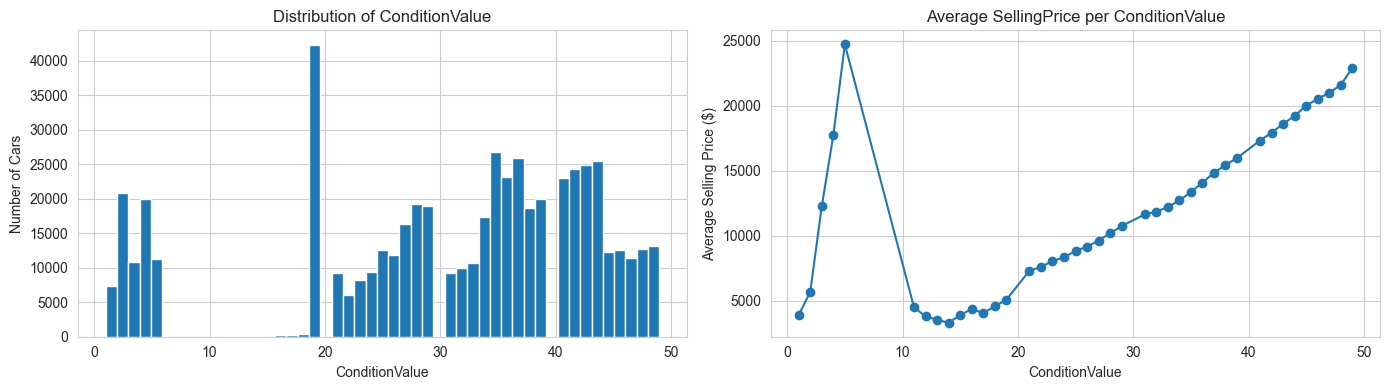

In [111]:
print(df["ConditionValue"].value_counts().sort_index().to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df["ConditionValue"].dropna(), bins=49)
axes[0].set_title("Distribution of ConditionValue")
axes[0].set_xlabel("ConditionValue")
axes[0].set_ylabel("Number of Cars")

# average price for each ConditionValue
avg_price = df.groupby("ConditionValue")["SellingPrice"].mean()
axes[1].plot(avg_price.index, avg_price.values, marker="o")
axes[1].set_title("Average SellingPrice per ConditionValue")
axes[1].set_xlabel("ConditionValue")
axes[1].set_ylabel("Average Selling Price ($)")

plt.tight_layout()
plt.show()

In [112]:
# how many rows are on the "1-5" side, and is there a gap before the next values?
cond = df["ConditionValue"].dropna()
low = (cond <= 5).sum()
print(f"Rows with ConditionValue 1-5: {low} ({low / len(cond) * 100:.1f}%)")
print("Largest value in the 1-5 group:", cond[cond <= 5].max())
print("Smallest value above 5:", cond[cond > 5].min())
print("Rows with a value between 6 and 10:", ((cond > 5) & (cond < 11)).sum())

Rows with ConditionValue 1-5: 70101 (12.8%)
Largest value in the 1-5 group: 5.0
Smallest value above 5: 11.0
Rows with a value between 6 and 10: 0


**Observation:** 70,101 rows (12.8% of the rows that have a `ConditionValue`) have values from 1 to 5. The next value in the data is 11 - there is **no row at all** with a value from 6 to 10 (see the counts above). The two groups are also clearly separated in the histogram.

**Insight:** a gap like this suggests two different scales mixed in one column: a small 1-5 scale and a bigger 11-49 scale. Both are useful on their own - inside each scale the value goes up with the price (correlation 0.655 for 1-5 and 0.524 for 11-49, shown below) - but a 5 and a 45 should not be compared as if they were the same kind of number. We do **not** multiply anything by 10 because we do not know the real meaning; the original values stay as they are, and a new `ConditionScale` column marks the group.

**Business Implication:** analyse condition within each scale (use `ConditionScale`), and ask the data owner what the two scales mean before using `ConditionValue` in any report or model.

### Fill missing numbers (median by Year, no rescaling)

**What:** fill missing `ConditionValue` and `Odometer` with the median of cars of the same `Year`. The original `ConditionValue` values are kept exactly as they are.

**Why:** the median is not pulled around by extreme values, and cars of the same year are more alike than the whole dataset. We do not change the scale of any value based on an assumption.

In [113]:
# fill missing numbers using the median for cars of the same Year (no rescaling)
df = fill_with_group_median(df, "ConditionValue", "Year")
df = fill_with_group_median(df, "Odometer", "Year")

# just in case a whole Year group had no data, fall back to the overall median
df["ConditionValue"] = df["ConditionValue"].fillna(df["ConditionValue"].median())
df["Odometer"] = df["Odometer"].fillna(df["Odometer"].median())

### Mark the two ConditionValue scales

**What:** add a `ConditionScale` column ("1-5" or "11-49") and measure the correlation between `ConditionValue` and `SellingPrice` inside each scale.

**Why:** the histogram suggests two groups. A new column lets us look at each group separately without touching `ConditionValue` itself (the original values stay exactly as they are).

In [114]:
# label each row with its scale - ConditionValue itself is NOT changed
df["ConditionScale"] = np.where(df["ConditionValue"] <= 5, "1-5", "11-49")
print(df["ConditionScale"].value_counts())

# correlation with SellingPrice inside each scale
for scale, group in df.groupby("ConditionScale"):
    corr_value = group["ConditionValue"].corr(group["SellingPrice"])
    print(f"Correlation of ConditionValue with SellingPrice (scale {scale}): {corr_value:.3f}")

ConditionScale
11-49    488496
1-5       70315
Name: count, dtype: int64
Correlation of ConditionValue with SellingPrice (scale 1-5): 0.655
Correlation of ConditionValue with SellingPrice (scale 11-49): 0.524


### Remove clear errors only

**What:** remove rows with a missing `MMR`, `SellingPrice` or `SaleDate`, `Odometer = 999999`, or `SellingPrice <= 1`, and print how many rows each rule removed.

**Why:** these are impossible or unusable values. Anything that is just unusual (very expensive, very cheap, very high mileage) is kept and handled in the outlier steps below.

In [115]:
# remove ONLY clear errors, one rule at a time, and print how many rows each rule removed
rules = {
    "missing MMR": df["MMR"].isna(),
    "missing SellingPrice": df["SellingPrice"].isna(),
    "missing SaleDate": df["SaleDate"].isna(),
    "Odometer = 999999 (placeholder)": df["Odometer"] == 999999,
    "SellingPrice <= 1": df["SellingPrice"] <= 1,
}

removed_counts = {}   # saved for the Validation section
for name, rule in rules.items():
    rule = rule.reindex(df.index, fill_value=False)   # keep the rule aligned with the rows still left
    removed_counts[name] = int(rule.sum())
    print(f"{name}: {rule.sum()} rows removed")
    df = df[~rule]

print("Rows left:", len(df))

missing MMR: 12 rows removed
missing SellingPrice: 0 rows removed
missing SaleDate: 0 rows removed
Odometer = 999999 (placeholder): 72 rows removed
SellingPrice <= 1: 4 rows removed
Rows left: 558723


### Look at SellingPrice vs MMR extremes (flag them, don't delete them)

**What:** look at the cars that sold for way more or way less than their estimated market price (`MMR`), then add a `PriceFlag` column instead of removing them.

**Why:** a big gap is not automatically a mistake (a rare trim, a damaged car, a special sale). Deleting these rows on an assumption would throw away real data, so we only mark them and let the analysis decide.

In [116]:
# biggest positive difference: sold for much MORE than expected
diff = df["SellingPrice"] - df["MMR"]
df.assign(PriceDiff=diff).nlargest(5, "PriceDiff")[["Year", "Make", "Model", "MMR", "SellingPrice", "PriceDiff"]]

,Year,Make,Model,MMR,SellingPrice,PriceDiff
344905,2014,ford,escape,22800.0,230000.0,207200.0
160201,2010,ford,escape,8250.0,108200.0,99950.0
407508,2012,nissan,versa,10350.0,67500.0,57150.0
405315,2015,toyota,corolla,15250.0,68900.0,53650.0
336652,2013,mercedes-benz,sprinter,31900.0,84000.0,52100.0


In [117]:
# biggest negative difference: sold for much LESS than expected
df.assign(PriceDiff=diff).nsmallest(5, "PriceDiff")[["Year", "Make", "Model", "MMR", "SellingPrice", "PriceDiff"]]

,Year,Make,Model,MMR,SellingPrice,PriceDiff
405316,2013,mercedes-benz,g-class,110000.0,22250.0,-87750.0
1723,2012,mercedes-benz,m-class,69000.0,18500.0,-50500.0
404667,2015,chevrolet,tahoe,52700.0,8500.0,-44200.0
505951,2014,chevrolet,corvette stingray,57600.0,15700.0,-41900.0
41815,2014,bmw,m5,76000.0,35000.0,-41000.0


In [118]:
# flag (do NOT remove) rows where the price is far from MMR
price_ratio = df["SellingPrice"] / df["MMR"].replace(0, np.nan)   # guard against MMR = 0
df["PriceFlag"] = np.select(
    [price_ratio > 5, price_ratio < 0.2],
    ["extreme_high", "extreme_low"],
    default="normal",
)
print(df["PriceFlag"].value_counts())

cols = ["Year", "Make", "Model", "MMR", "SellingPrice"]

# 10 most extreme rows on each side (ratio = SellingPrice / MMR)
print("\n10 most extreme HIGH rows:")
display(df[df["PriceFlag"] == "extreme_high"].assign(Ratio=price_ratio.round(2)).nlargest(10, "Ratio")[cols + ["Ratio"]])

print("10 most extreme LOW rows:")
display(df[df["PriceFlag"] == "extreme_low"].assign(Ratio=price_ratio.round(2)).nsmallest(10, "Ratio")[cols + ["Ratio"]])

PriceFlag
normal          557085
extreme_low       1417
extreme_high       221
Name: count, dtype: int64

10 most extreme HIGH rows:


,Year,Make,Model,MMR,SellingPrice,Ratio
22116,2005,chevrolet,silverado 3500,75.0,6100.0,81.33
246056,2003,lincoln,town car,25.0,1800.0,72.00
150000,2005,ford,explorer,25.0,1500.0,60.00
7446,2003,chevrolet,astro cargo,25.0,1400.0,56.00
196104,2004,ford,f-150 heritage,25.0,1300.0,52.00
542326,2002,mercedes-benz,s-class,50.0,2200.0,44.00
83935,2005,hyundai,sonata,50.0,2000.0,40.00
258725,2009,ford,f250,175.0,6400.0,36.57
28688,2000,chevrolet,tahoe,25.0,900.0,36.00
308327,1999,bmw,3 series,50.0,1800.0,36.00


10 most extreme LOW rows:


,Year,Make,Model,MMR,SellingPrice,Ratio
17608,2007,chevrolet,tahoe,17250.0,300.0,0.02
164494,2013,dodge,avenger,12400.0,300.0,0.02
210931,2011,ford,f-150,26600.0,600.0,0.02
233032,2003,chevrolet,silverado 1500,10100.0,250.0,0.02
361037,2004,dodge,ram pickup 1500,20700.0,400.0,0.02
413223,2013,dodge,grand caravan,14050.0,300.0,0.02
20391,2006,ford,f-150,10800.0,350.0,0.03
23908,2004,chevrolet,tahoe,9325.0,300.0,0.03
25708,2003,dodge,ram pickup 3500,27200.0,700.0,0.03
47447,2005,ford,mustang,7975.0,200.0,0.03


### Outlier summary (IQR + percentiles + boxplots)

**What:** for `SellingPrice`, `MMR` and `Odometer`, count the values outside the IQR fences (Q1 - 1.5*IQR, Q3 + 1.5*IQR), show key percentiles, and draw boxplots.

**Why:** this shows how many extreme values there really are and how far out they go, without deleting anything.

In [119]:
rows = []
for col in ["SellingPrice", "MMR", "Odometer"]:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr   # standard IQR fences
    rows.append({
        "Column": col,
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "LowerFence": low, "UpperFence": high,
        "OutliersBelow": (df[col] < low).sum(),
        "OutliersAbove": (df[col] > high).sum(),
        "P1": df[col].quantile(0.01), "P5": df[col].quantile(0.05),
        "P95": df[col].quantile(0.95), "P99": df[col].quantile(0.99),
    })

pd.DataFrame(rows).set_index("Column").round(0)

,Q1,Q3,IQR,LowerFence,UpperFence,OutliersBelow,OutliersAbove,P1,P5,P95,P99
Column,,,,,,,,,,,
SellingPrice,6900.0,18200.0,11300.0,-10050.0,35150.0,0,16354,500.0,1500.0,30600.0,44900.0
MMR,7100.0,18300.0,11200.0,-9700.0,35100.0,0,16315,750.0,1800.0,30600.0,44900.0
Odometer,28374.0,99114.0,70739.0,-77734.0,205222.0,0,10300,3308.0,10518.0,169962.0,226221.0


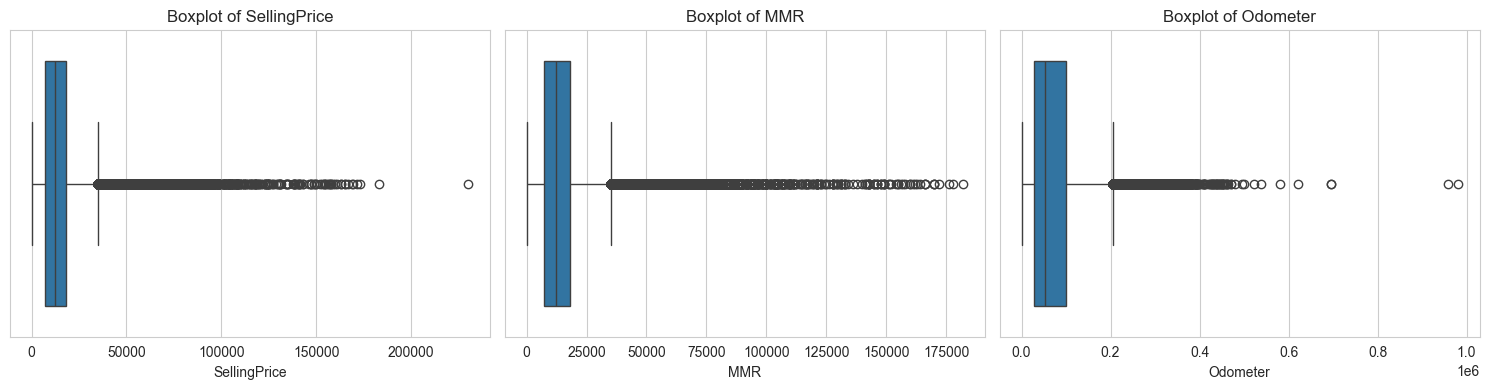

In [120]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["SellingPrice", "MMR", "Odometer"]):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

**Note:** an outlier is not necessarily an error. Expensive luxury cars and high-mileage cars are real, so they show up as outliers on the boxplots but are kept in the data. Only the clear errors above were removed.

**Observation:** the IQR rule marks 16,354 `SellingPrice` values above $35,150, 16,315 `MMR` values above $35,100, and 10,300 `Odometer` values above 205,222 miles. Nothing falls below the lower fence because the fences are negative.

**Insight:** `SellingPrice` and `MMR` have almost the same number of outliers - these are real expensive cars (luxury and new models), not typing mistakes. The `Odometer` outliers are cars with a very high but possible mileage. All of them are kept.

**Business Implication:** the expensive cars pull the average up (mean $13,613 vs median $12,100), so use the median when describing a "typical" price, and look at the luxury segment separately.

In [121]:
# drop only rows that are identical in every column except Id
# (every row has a different Id, so including Id would never find a duplicate)
dup_cols = df.columns.drop("Id")
dup_count = df.duplicated(subset=dup_cols).sum()
print("Rows identical in every column except Id (dropped):", dup_count)
df = df.drop_duplicates(subset=dup_cols)

print("Rows left after cleaning:", len(df))
print("Missing values left:", df.isnull().sum().sum())

Rows identical in every column except Id (dropped): 0
Rows left after cleaning: 558723
Missing values left: 0


## 6. Create a Few New Columns

In [122]:
# how old was the car when it was sold?
df["CarAge"] = df["SaleDate"].dt.year - df["Year"]

# how does the selling price compare to the estimated market price (MMR)?
df["PriceDiff"] = df["SellingPrice"] - df["MMR"]

df[["CarAge", "PriceDiff"]].describe()

,CarAge,PriceDiff
count,558723.000000,558723.000000
mean,4.864684,-157.711410
std,3.943616,1758.109488
min,-1.000000,-87750.000000
25%,2.000000,-800.000000
50%,3.000000,-50.000000
75%,7.000000,650.000000
max,33.000000,207200.000000


### More new columns

**What:** add `SaleYear`, `SaleQuarter`, `PriceDiffPct`, `PriceStatus`, `MileageBand` and `PriceBand` (`CarAge` and `PriceDiff` above stay the same).

**Why:** a % difference is easier to compare across cheap and expensive cars than a $ difference, and bands turn continuous numbers into a few groups that are easy to count and plot. Labels use plain `-` hyphens (no en-dashes) so Excel opens the CSV without garbled text.

In [123]:
# when was the car sold?
df["SaleYear"] = df["SaleDate"].dt.year
df["SaleQuarter"] = "Q" + df["SaleDate"].dt.quarter.astype(str)

# price difference in % (MMR = 0 would divide by zero, so those rows get NaN instead)
safe_mmr = df["MMR"].replace(0, np.nan)
df["PriceDiffPct"] = (df["SellingPrice"] - df["MMR"]) / safe_mmr * 100

# Above / Below / At MMR (within 1% counts as "At MMR")
df["PriceStatus"] = np.select(
    [df["PriceDiffPct"] > 1, df["PriceDiffPct"] < -1],
    ["Above MMR", "Below MMR"],
    default="At MMR",
)

# group mileage and price into bands (plain "-" in labels so Excel shows them correctly)
df["MileageBand"] = pd.cut(
    df["Odometer"],
    bins=[0, 25000, 50000, 75000, 100000, np.inf],
    labels=["0-25K", "25K-50K", "50K-75K", "75K-100K", "100K+"],
    right=False,
).astype(str)

df["PriceBand"] = pd.cut(
    df["SellingPrice"],
    bins=[0, 5000, 10000, 20000, 30000, np.inf],
    labels=["Under 5K", "5K-10K", "10K-20K", "20K-30K", "30K+"],
    right=False,
).astype(str)

for col in ["SaleQuarter", "PriceStatus", "MileageBand", "PriceBand"]:
    print(df[col].value_counts(), "\n")

SaleQuarter
Q1    350163
Q2    153792
Q4     53511
Q3      1257
Name: count, dtype: int64 

PriceStatus
Below MMR    262458
Above MMR    237671
At MMR        58594
Name: count, dtype: int64 

MileageBand
25K-50K     151648
100K+       137272
0-25K       118463
50K-75K      85859
75K-100K     65481
Name: count, dtype: int64 

PriceBand
10K-20K     232706
5K-10K      109911
Under 5K    102271
20K-30K      83089
30K+         30746
Name: count, dtype: int64 



## 7. Univariate Analysis (One Column at a Time)

Four charts in one 2x2 grid using `plt.subplots()`.

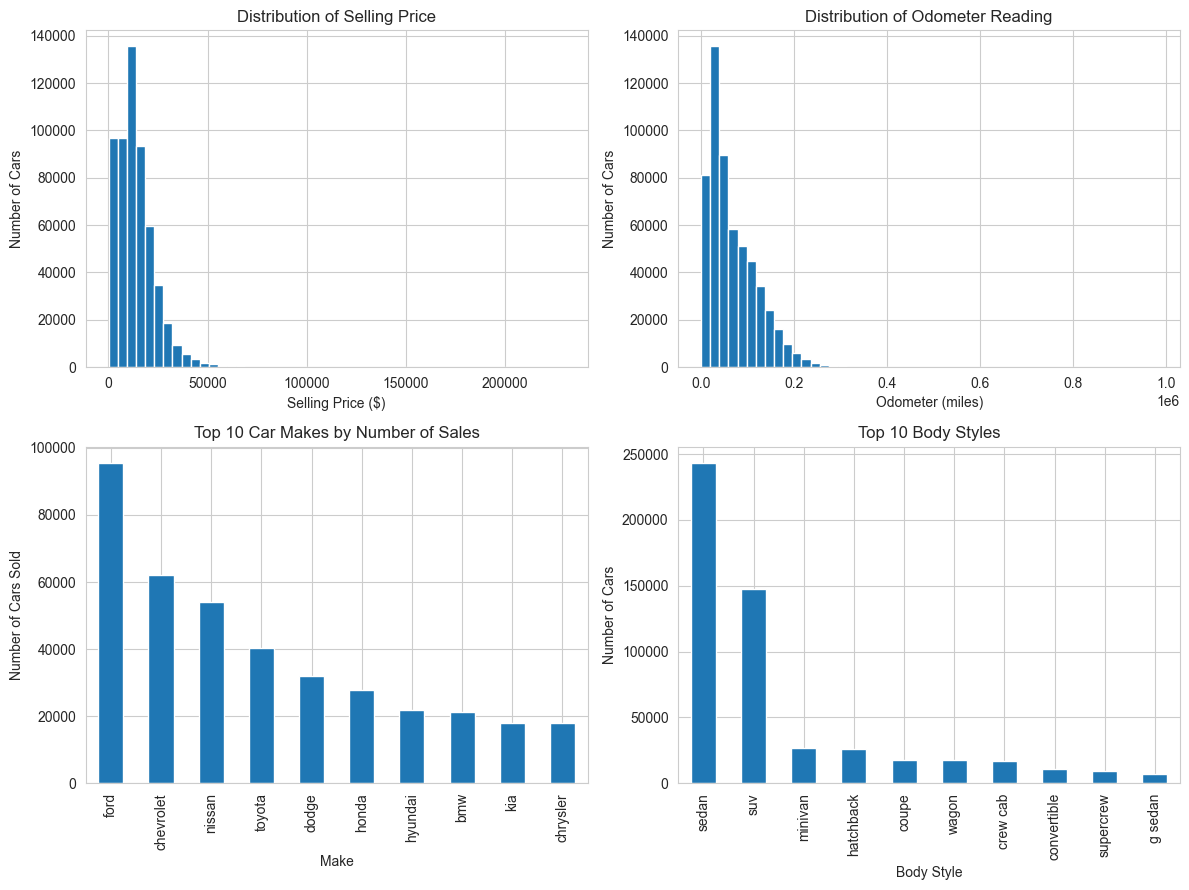

In [124]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].hist(df["SellingPrice"], bins=50)
axes[0, 0].set_title("Distribution of Selling Price")
axes[0, 0].set_xlabel("Selling Price ($)")
axes[0, 0].set_ylabel("Number of Cars")

axes[0, 1].hist(df["Odometer"], bins=50)
axes[0, 1].set_title("Distribution of Odometer Reading")
axes[0, 1].set_xlabel("Odometer (miles)")
axes[0, 1].set_ylabel("Number of Cars")

df["Make"].value_counts().head(10).plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Top 10 Car Makes by Number of Sales")
axes[1, 0].set_xlabel("Make")
axes[1, 0].set_ylabel("Number of Cars Sold")

df["Body"].value_counts().head(10).plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Top 10 Body Styles")
axes[1, 1].set_xlabel("Body Style")
axes[1, 1].set_ylabel("Number of Cars")

plt.tight_layout()
plt.show()

**Observation:** `SellingPrice` and `Odometer` are both right-skewed: most cars are cheap or low-mileage, with a long tail of expensive or high-mileage ones (price mean $13,613 vs median $12,100; odometer mean 68,213 vs median 52,258 miles). Ford (95,578 sales), Chevrolet (61,995) and Nissan (54,059) are the top makes, and sedans (43.6%) and SUVs (26.4%) are the most common body styles.

**Insight:** this is mostly a market of everyday, mainstream used cars, led by three big brands and two body styles.

**Business Implication:** inventory, pricing and marketing should focus on mainstream sedans and SUVs from the top brands, because that is where most of the volume is.

## 8. Bivariate Analysis (Comparing Two Columns)

Three charts in one row, sharing the same figure.

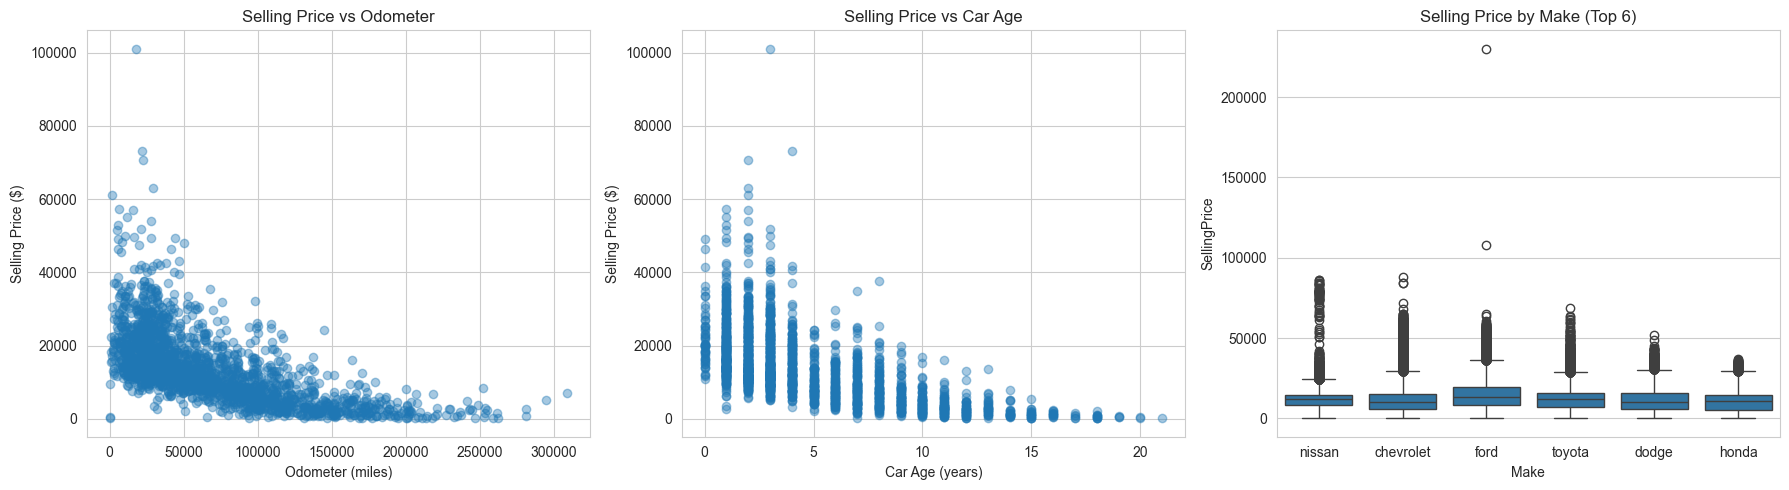

In [125]:
# take a random sample so the scatter plots aren't too crowded
sample = df.sample(2000, random_state=1)
top_makes = df["Make"].value_counts().head(6).index
df_top_makes = df[df["Make"].isin(top_makes)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(sample["Odometer"], sample["SellingPrice"], alpha=0.4)
axes[0].set_title("Selling Price vs Odometer")
axes[0].set_xlabel("Odometer (miles)")
axes[0].set_ylabel("Selling Price ($)")

axes[1].scatter(sample["CarAge"], sample["SellingPrice"], alpha=0.4)
axes[1].set_title("Selling Price vs Car Age")
axes[1].set_xlabel("Car Age (years)")
axes[1].set_ylabel("Selling Price ($)")

sns.boxplot(data=df_top_makes, x="Make", y="SellingPrice", ax=axes[2])
axes[2].set_title("Selling Price by Make (Top 6)")

plt.tight_layout()
plt.show()

**Observation:** `SellingPrice` goes down as `Odometer` (correlation -0.59) and `CarAge` (-0.58) go up. The scatter plots are wide, so many cars with the same mileage or age still have very different prices. The boxplot shows clear price differences between makes.

**Insight:** age and mileage matter, but they do not explain the price on their own - the make and model matter a lot too.

**Business Implication:** when estimating a price, use age and mileage together with the make and model, not mileage alone.

## 9. Multivariate Analysis (Correlation Between Numbers)

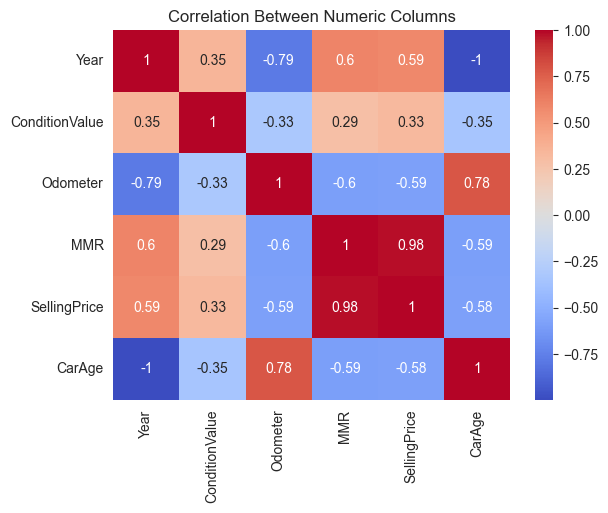

In [126]:
num_cols = ["Year", "ConditionValue", "Odometer", "MMR", "SellingPrice", "CarAge"]
corr = df[num_cols].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Between Numeric Columns")
plt.show()

**Observation:** `SellingPrice` and `MMR` are almost perfectly correlated (0.98). `Year` has a positive correlation with price (0.59), while `Odometer` (-0.59) and `CarAge` (-0.58) are negative. `ConditionValue` is much weaker (0.33).

**Insight:** MMR is a very good estimate of the selling price. The weak `ConditionValue` link is partly because the column mixes two scales (inside each scale the correlation is 0.52 to 0.66).

**Business Implication:** use MMR as the starting point for pricing, and treat `ConditionValue` carefully until its scales are explained. A strong correlation does not prove that one column causes the other.

## 10. Sales Over Time

Note: the data runs from January 2014 to July 20, 2015 - **July 2015 is a partial month**, so it will look artificially low on the chart even though sales didn't actually drop.

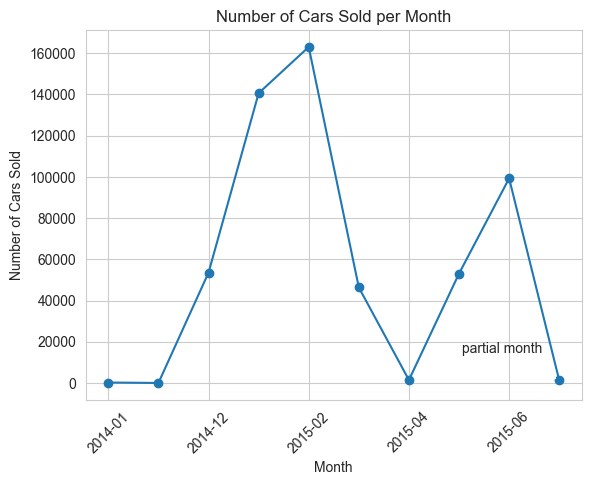

In [127]:
df["SaleMonth"] = df["SaleDate"].dt.strftime("%Y-%m")
monthly_sales = df.groupby("SaleMonth").size()

monthly_sales.plot(kind="line", marker="o")
plt.title("Number of Cars Sold per Month")
plt.xlabel("Month")
plt.ylabel("Number of Cars Sold")
plt.xticks(rotation=45)

# mark the last point as a partial month instead of letting it look like a real drop
plt.annotate("partial month", xy=(len(monthly_sales) - 1, monthly_sales.iloc[-1]),
             xytext=(-70, 20), textcoords="offset points", arrowprops=dict(arrowstyle="->"))

plt.show()

**Observation:** sales per month are: Dec 2014 = 53,511, Jan 2015 = 140,587, Feb = 163,033, Mar = 46,336, **Apr = 1,436**, May = 53,088, Jun = 99,268, and Jul = 1,257 (partial month, until July 20). January-November 2014 together have only 207 rows.

**Insight:** the very low April 2015 looks like a gap in the data, not a real drop in sales (March had 46,336 and May had 53,088). The data is really a Dec 2014 - Jun 2015 sample, not a full history.

**Business Implication:** do not draw seasonal conclusions or build a forecast from these months until the source confirms why April and most of 2014 are almost empty.

## 11. Business Questions (Extra EDA)

Four questions a business reader would ask. Each one has a table or chart and a short Observation / Insight / Business Implication note.

### Top 10 Makes: by total sales value and by average price

**What:** rank makes by the total money sold, and by the average selling price (only makes with at least 100 sales, so a tiny make with one expensive car can't win).

**Why:** total value shows where the money is made; average price shows which makes are premium.

Top 10 makes by total sales value:


,TotalSalesValue,AvgPrice,Sales
Make,,,
ford,1.371579e+09,14350.0,95578
chevrolet,7.353520e+08,11861.0,61995
nissan,6.337453e+08,11723.0,54059
toyota,4.913508e+08,12213.0,40233
bmw,4.628260e+08,21760.0,21270
mercedes-benz,3.720172e+08,21435.0,17356
dodge,3.522976e+08,11033.0,31931
infiniti,3.137800e+08,20277.0,15475
honda,3.001693e+08,10810.0,27769


Top 10 makes by average selling price (at least 100 sales):


,TotalSalesValue,AvgPrice,Sales
Make,,,
bentley,8626650.0,74368.0,116
maserati,6375300.0,43968.0,145
porsche,59382051.0,39326.0,1510
land rover,66143205.0,27640.0,2393
ram,115721911.0,25300.0,4574
bmw,462826013.0,21760.0,21270
mercedes-benz,372017240.0,21435.0,17356
infiniti,313779990.0,20277.0,15475
lexus,247737805.0,19960.0,12412


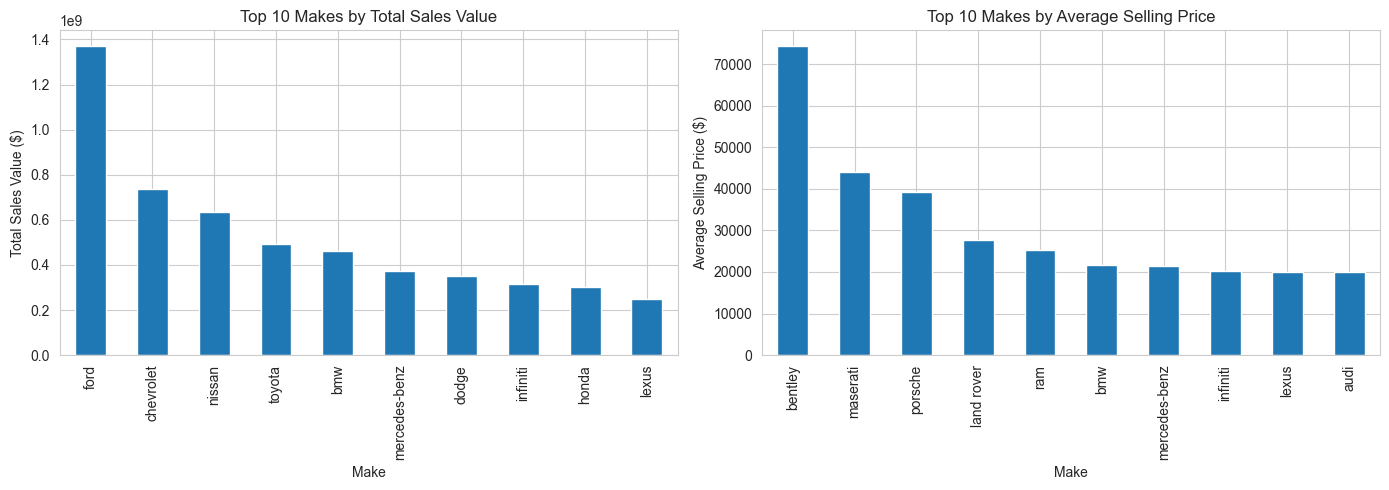

In [128]:
make_stats = df.groupby("Make").agg(
    TotalSalesValue=("SellingPrice", "sum"),
    AvgPrice=("SellingPrice", "mean"),
    Sales=("SellingPrice", "size"),
)
top_value = make_stats.sort_values("TotalSalesValue", ascending=False).head(10)
top_avg = make_stats[make_stats["Sales"] >= 100].sort_values("AvgPrice", ascending=False).head(10)

print("Top 10 makes by total sales value:")
display(top_value.round(0))
print("Top 10 makes by average selling price (at least 100 sales):")
display(top_avg.round(0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_value["TotalSalesValue"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Top 10 Makes by Total Sales Value")
axes[0].set_ylabel("Total Sales Value ($)")
top_avg["AvgPrice"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Top 10 Makes by Average Selling Price")
axes[1].set_ylabel("Average Selling Price ($)")
plt.tight_layout()
plt.show()

**Observation:** Ford is first by total sales value ($1.37 billion from 95,578 sales), then Chevrolet ($735 million) and Nissan ($634 million). BMW is 5th by value ($463 million) with only 21,270 sales. By average price (makes with at least 100 sales), Bentley is first ($74,368), then Maserati ($43,968) and Porsche ($39,326).

**Insight:** big-volume brands win on total money, while luxury brands win on money per car. BMW and Mercedes-Benz make the top 10 of both lists.

**Business Implication:** volume brands bring the revenue, but luxury cars bring more revenue per car handled. A balanced stock of both can protect the business.

### Top 10 Models by sales volume

**What:** count the sales of each model (Make + Model together, because the same model name can exist under different makes).

**Why:** the best-selling models show what buyers actually want.

Top 10 models by number of sales:


,Sales
nissan altima,19346
ford f-150,14689
ford fusion,12945
toyota camry,12549
ford escape,11986
ford focus,10407
honda accord,9164
bmw 3 series,8209
chevrolet impala,8090
dodge grand caravan,8069


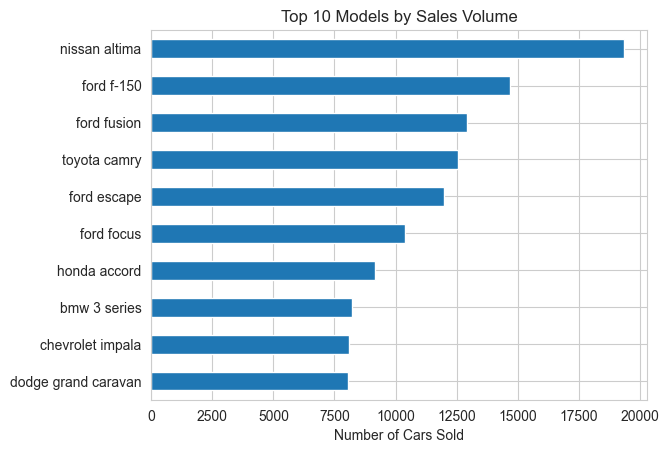

In [129]:
model_counts = (df["Make"] + " " + df["Model"]).value_counts().head(10)
print("Top 10 models by number of sales:")
display(model_counts.to_frame("Sales"))

model_counts.sort_values().plot(kind="barh")
plt.title("Top 10 Models by Sales Volume")
plt.xlabel("Number of Cars Sold")
plt.show()

**Observation:** the best seller is the Nissan Altima (19,346 sales), followed by Ford F-150 (14,689), Ford Fusion (12,945), Toyota Camry (12,549) and Ford Escape (11,986). Four of the top 10 are Ford models.

**Insight:** demand is concentrated in a small group of popular, mainstream models.

**Business Implication:** keep these models in stock and watch their prices closely, since they drive the most transactions.

### Top 10 Sellers by number of transactions

**What:** count the transactions of each seller and show each seller's share of all sales.

**Why:** it shows whether sales depend on a few big sellers or are spread out.

Top 10 sellers:


,Transactions,ShareOfSalesPct
Seller,,
nissan-infiniti lt,19693,3.52
ford motor credit company llc,19162,3.43
the hertz corporation,18299,3.28
santander consumer,15260,2.73
avis corporation,12540,2.24
nissan infiniti lt,9962,1.78
wells fargo dealer services,8792,1.57
tdaf remarketing,7209,1.29
enterprise veh exchange/rental,6853,1.23


Combined share of the top 10 sellers (%): 22.27


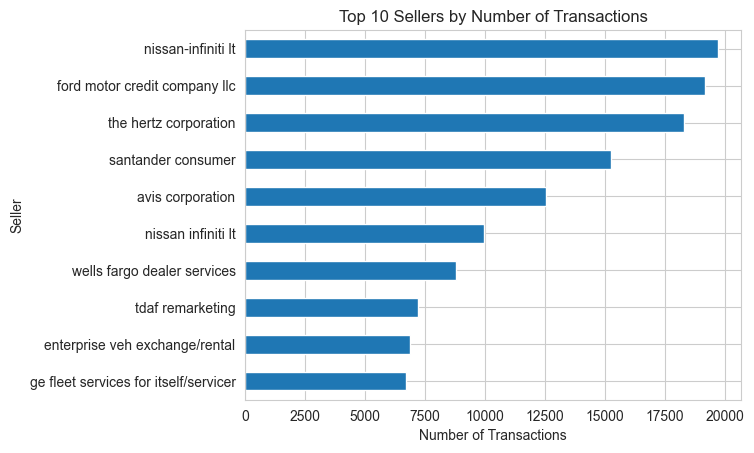

In [130]:
seller_counts = df["Seller"].value_counts().head(10)
seller_table = pd.DataFrame({
    "Transactions": seller_counts,
    "ShareOfSalesPct": (seller_counts / len(df) * 100).round(2),
})
print("Top 10 sellers:")
display(seller_table)
print("Combined share of the top 10 sellers (%):", seller_table["ShareOfSalesPct"].sum().round(2))

seller_counts.sort_values().plot(kind="barh")
plt.title("Top 10 Sellers by Number of Transactions")
plt.xlabel("Number of Transactions")
plt.show()

**Observation:** the top 10 sellers together make 22.27% of all sales. The largest are nissan-infiniti lt (19,693 sales, 3.52%), ford motor credit company llc (19,162, 3.43%) and the hertz corporation (18,299, 3.28%). The names "nissan-infiniti lt" and "nissan infiniti lt" (9,962 sales) look like the same seller written two ways; together they would be about 5.3% of sales.

**Insight:** sales are spread over thousands of sellers, with a few finance companies, rental companies and manufacturers on top. No single seller is above about 5% of the volume.

**Business Implication:** the business does not depend on one seller, but the biggest ones are worth strong relationships. The seller names should be standardised further for a more exact ranking.

### Sales Above / At / Below MMR

**What:** count and percent of sales for each `PriceStatus` (within 1% of MMR counts as "At MMR").

**Why:** MMR is the market estimate, so this shows whether cars usually sell for more or less than expected.

,Sales,Percent
PriceStatus,,
Below MMR,262458,46.97
Above MMR,237671,42.54
At MMR,58594,10.49


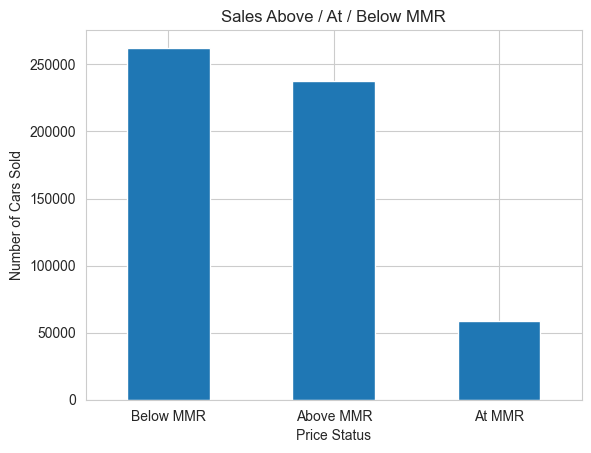

In [131]:
status_counts = df["PriceStatus"].value_counts()
status_table = pd.DataFrame({
    "Sales": status_counts,
    "Percent": (status_counts / len(df) * 100).round(2),
})
display(status_table)

status_counts.plot(kind="bar")
plt.title("Sales Above / At / Below MMR")
plt.xlabel("Price Status")
plt.ylabel("Number of Cars Sold")
plt.xticks(rotation=0)
plt.show()

**Observation:** 46.97% of the sales (262,458) were below MMR, 42.54% (237,671) above MMR, and 10.49% (58,594) within 1% of MMR. The average `PriceDiff` is -$157.71.

**Insight:** MMR is a fair estimate - cars sell slightly under it on average (about 1.1% of the average MMR), and the above / below split is fairly balanced.

**Business Implication:** use MMR as a pricing guide with a small discount in mind, and note that over 4 in 10 cars still sell above MMR, so there is room to price higher in some cases.

## 12. KPI Table

**What:** the main numbers of the final dataset in one small table.

**Why:** one place to read the size and the price level of the business at a glance.

In [132]:
# KPIs calculated on all rows of the final dataset
kpi = pd.Series({
    "Total Vehicles Sold": f"{len(df):,}",
    "Total Sales Value": f"${df['SellingPrice'].sum():,.0f}",
    "Average Selling Price": f"${df['SellingPrice'].mean():,.2f}",
    "Median Selling Price": f"${df['SellingPrice'].median():,.2f}",
    "Average MMR": f"${df['MMR'].mean():,.2f}",
    "Average PriceDiff": f"${df['PriceDiff'].mean():,.2f}",
    "% Sold Above MMR": f"{(df['PriceStatus'] == 'Above MMR').mean() * 100:.2f}%",
    "% Sold Below MMR": f"{(df['PriceStatus'] == 'Below MMR').mean() * 100:.2f}%",
    "Average Vehicle Age (CarAge)": f"{df['CarAge'].mean():.2f} years",
    "Average Odometer": f"{df['Odometer'].mean():,.0f} miles",
    "Number of Makes": df["Make"].nunique(),
    "Number of Models": df["Model"].nunique(),
}, name="Value")
kpi.to_frame()

,Value
Total Vehicles Sold,"558,723"
Total Sales Value,"$7,605,885,333"
Average Selling Price,"$13,612.98"
Median Selling Price,"$12,100.00"
Average MMR,"$13,770.69"
Average PriceDiff,$-157.71
% Sold Above MMR,42.54%
% Sold Below MMR,46.97%
Average Vehicle Age (CarAge),4.86 years
Average Odometer,"68,213 miles"


## 13. Key Takeaways

- **Size:** the final dataset has 558,723 rows (114 of the 558,837 raw rows were removed, 0.02%), with $7.61 billion in total sales, an average price of $13,613 and a median of $12,100.
- **MMR is a good guide:** `SellingPrice` and `MMR` have a 0.98 correlation; 47.0% of cars sold below MMR, 42.5% above and 10.5% at MMR, with an average difference of -$158.
- **Age and mileage lower the price:** the correlation with `SellingPrice` is -0.59 for `Odometer` and -0.58 for `CarAge`.
- **Top brands:** Ford, Chevrolet and Nissan lead both in volume and in total sales value (Ford: $1.37 billion), while luxury makes lead in average price (Bentley $74,368, Maserati $43,968, Porsche $39,326).
- **Many sellers:** the top 10 sellers account for only 22.3% of sales, and the largest single seller (nissan-infiniti lt) has 3.5%.
- **ConditionValue has two scales:** 12.8% of the values are 1-5, nothing falls between 6 and 10, and the values 11-49 follow. Inside each scale the value rises with price (correlation 0.66 and 0.52).
- **Extreme prices are kept, but flagged:** 1,638 rows are flagged (221 `extreme_high`, 1,417 `extreme_low`); 145 of the `extreme_high` rows have an MMR below $200, which looks like a placeholder MMR.
- **Time coverage is narrow:** 99.7% of the sales are between December 2014 and June 2015, and April 2015 has only 1,436 rows (March has 46,336).

## 14. Validation

**What:** a before-vs-after table of how many rows each cleaning step removed, plus the final shape, missing values, data types and numeric ranges.

**Why:** it shows that the cleaning only removed what we said it removed, and that the final dataset is complete and sensible. All numbers come from the code above, not typed by hand.

In [133]:
# rows we started with = every row in the first (shifted-rows) mask
raw_rows = len(shifted_rows)

steps = {"Shifted rows (VIN / State)": int(shifted_rows.sum())}
steps.update(removed_counts)
steps["Duplicates (ignoring Id)"] = int(dup_count)

remaining = raw_rows
table = [{"Step": "Raw data", "Rows removed": 0, "Rows remaining": raw_rows}]
for step, count in steps.items():
    remaining -= count
    table.append({"Step": step, "Rows removed": count, "Rows remaining": remaining})
display(pd.DataFrame(table))

print("Final rows:", len(df), "| matches the table:", remaining == len(df))
print("Final shape:", df.shape)
print("Missing values left:", df.isnull().sum().sum())

,Step,Rows removed,Rows remaining
0,Raw data,0,558837
1,Shifted rows (VIN / State),26,558811
2,missing MMR,12,558799
3,missing SellingPrice,0,558799
4,missing SaleDate,0,558799
5,Odometer = 999999 (placeholder),72,558727
6,SellingPrice <= 1,4,558723
7,Duplicates (ignoring Id),0,558723


Final rows: 558723 | matches the table: True
Final shape: (558723, 28)
Missing values left: 0


In [134]:
# data types and numeric ranges of the final dataset
display(df.dtypes.to_frame("dtype"))
display(df.describe().T[["min", "max"]])

,dtype
Id,int64
Year,int64
Make,object
Model,object
Trim,object
Body,object
Transmission,object
VIN,object
State,object
ConditionValue,float64


,min,max
Id,2.0,558838.0
Year,1982.0,2015.0
ConditionValue,1.0,49.0
Odometer,1.0,980113.0
MMR,25.0,182000.0
SellingPrice,100.0,230000.0
SaleDate,2014-01-01 01:15:00,2015-07-20 19:30:00
CarAge,-1.0,33.0
PriceDiff,-87750.0,207200.0
SaleYear,2014.0,2015.0


In [135]:
# numbers used in the Limitations section
print("Rows with MMR below 200:", (df["MMR"] < 200).sum())
print("extreme_high rows:", (df["PriceFlag"] == "extreme_high").sum())
print("extreme_high rows with MMR below 200:", ((df["PriceFlag"] == "extreme_high") & (df["MMR"] < 200)).sum())
print("Sales per month:")
print(df.groupby("SaleMonth").size().to_string())

Rows with MMR below 200: 277
extreme_high rows: 221
extreme_high rows with MMR below 200: 145
Sales per month:
SaleMonth
2014-01       206
2014-02         1
2014-12     53511
2015-01    140587
2015-02    163033
2015-03     46336
2015-04      1436
2015-05     53088
2015-06     99268
2015-07      1257


## 15. Limitations

- **Historical data:** these are past auction sales, so prices and the market may be different today.
- **Narrow date range:** the data covers January 2014 to July 2015, but most sales (99.7%) are between December 2014 and June 2015. January-November 2014 has only 207 rows, and July 2015 is a partial month.
- **Apparent gap in April 2015:** only 1,436 sales, against 46,336 in March and 53,088 in May. This looks like missing data, so monthly trends should be read with care.
- **ConditionValue is not documented:** it seems to have two scales (1-5 and 11-49, nothing in between). We kept the original values and added `ConditionScale`, but its real meaning is unknown.
- **Correlation is not causation:** a link between two columns (for example mileage and price) does not prove that one causes the other.
- **Suspicious MMR values:** 277 rows have an MMR below 200. Many `extreme_high` rows (145 of 221) are in this group, with an MMR such as 25 or 50, which looks like a placeholder value in MMR and not a wrong `SellingPrice`. These rows are flagged, not removed.
- **Some text is still messy:** for example, the same seller can appear with slightly different names.

## 16. Export the Final Dataset

**What:** save the cleaned data as a CSV and a Parquet file (other files in the folder are not touched).

**Why:** CSV opens in Excel / Power BI; Parquet keeps the data types (for example `SaleDate` stays a real datetime).

In [136]:
# save the final dataset (SaleDate stays a datetime in the Parquet file)
df.to_csv("vehicle_sales_clean.csv", index=False, encoding="utf-8")
df.to_parquet("vehicle_sales_clean.parquet", index=False)
print("Saved vehicle_sales_clean.csv and vehicle_sales_clean.parquet")
print("Columns:", list(df.columns))

conn.close()
print("Closed the database connection.")

Saved vehicle_sales_clean.csv and vehicle_sales_clean.parquet
Columns: ['Id', 'Year', 'Make', 'Model', 'Trim', 'Body', 'Transmission', 'VIN', 'State', 'ConditionValue', 'Odometer', 'Color', 'Interior', 'Seller', 'MMR', 'SellingPrice', 'SaleDate', 'ConditionScale', 'PriceFlag', 'CarAge', 'PriceDiff', 'SaleYear', 'SaleQuarter', 'PriceDiffPct', 'PriceStatus', 'MileageBand', 'PriceBand', 'SaleMonth']
Closed the database connection.
